# Deep Learning Model Training for Customer Sentiment Analysis


In this walkthrough, you will train and fine-tune a deep learning model to analyze customer feedback and provide actionable insights.

**Scenario:**
Your retail client needs a sentiment analysis model to categorize customer reviews as positive, neutral, or negative and identify trends to enhance their strategy.

**Objective:**
- Preprocess a synthetic dataset of customer reviews for model training.
- Train a sentiment analysis model using an LSTM or fine-tune a pre-trained transformer like BERT.
- Measure accuracy, F1-score, and confusion matrix; identify areas for improvement.
- Deliver a brief summary of key trends, model performance, and recommendations (e.g., addressing delivery complaints).
- Discuss how to explain findings and next steps to a non-technical client.




### Part 1: Load the 'product_reviews.csv' dataset into a pandas DataFrame

In this section, we'll load the customer reviews dataset and perform exploratory data analysis to understand the distribution of sentiments and prepare the data for model training.

In [14]:
import pandas as pd

In [20]:
data=pd.read_csv("data/prod_reviews.csv")



In [18]:
# TODO: Display the first 10 rows using head(10)
data.head(10)

,Review,Sentiment
0,This product exceeded my expectations! It's hi...,Positive
1,"The product was decent. It worked fine, but it...",Neutral
2,I had a terrible experience with this company....,Negative
3,It's an okay product. Nothing to write home ab...,Neutral
4,Disappointed with the product. It didn't meet ...,Negative
5,Avoid this company at all costs. The service i...,Negative
6,I had a terrible experience with this company....,Negative
7,Avoid this company at all costs. The service i...,Negative
8,This product exceeded my expectations! It's hi...,Positive
9,This product is outstanding! It's exactly what...,Positive


In [21]:
# TODO: Get basic information about the dataset using describe()
data.describe()

,Review,Sentiment
count,395,395
unique,140,3
top,Fantastic customer service! The representative...,Positive
freq,22,138


In [22]:
# TODO: Display dataset information using info()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Review     395 non-null    object
 1   Sentiment  395 non-null    object
dtypes: object(2)
memory usage: 6.3+ KB


In [23]:
# TODO: Count the frequency of each sentiment using value_counts()
data["Sentiment"].value_counts()

Positive    138
Negative    129
Neutral     128
Name: Sentiment, dtype: int64

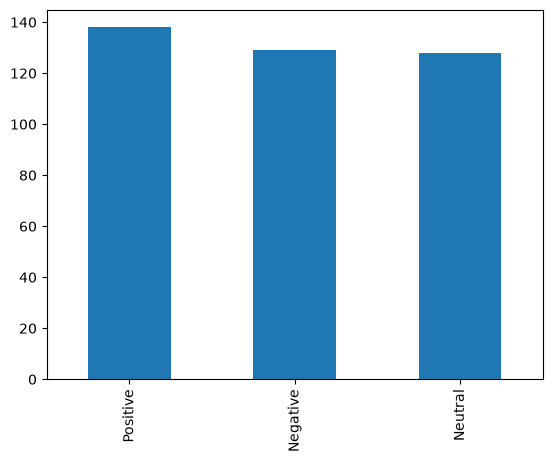

In [24]:
# TODO: Import matplotlib.pyplot for visualization
import matplotlib.pyplot as plt 
data["Sentiment"].value_counts().plot(kind='bar')
plt.show()

In [25]:
# TODO: Create a bar plot to visualize sentiment distribution
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import tensorflow as tf

from sklearn.model_selection import train_test_split
import sklearn

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

# downloading punkt sentence tokenizer models
nltk.download('punkt')
# downloading stopwords from nltk library
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Review text Cleaning
def clean_reviews(text):
    
    # removing html brackets and other square brackets from the string using regex
    regex = re.compile('<.*?>') # r'<.*?>'
    text = re.sub(regex, '', text)

    # removing special characters like @, #, $, etc
    pattern = re.compile('[^a-zA-z0-9\s]')
    text = re.sub(pattern,'',text)

    # removing numbers
    pattern = re.compile('\d+')
    text = re.sub(pattern,'',text)

    # converting text to lower case
    text = text.lower()
    
    # Tokenization of words
    text = word_tokenize(text)
    
    # Stop words removal
    text = [word for word in text if not word in stop_words]
    
    return ' '.join(text)

2026-10-20 20:47:53.872997: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-20 20:47:54.057843: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-20 20:47:54.813517: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 20:47:54.813559: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 20:47:54.986615: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

In [32]:
data['Review'] = data['Review'].apply(clean_reviews)

**Data Preprocessing**

Now we'll clean and preprocess the text data to prepare it for the LSTM model. Raw text data contains many elements that can interfere with machine learning models, such as HTML tags, special characters, numbers, and common words (stopwords) that don't carry meaningful sentiment information. We are creating a function called clean_reviews() that will systematically remove these unwanted elements and standardize the text format. This preprocessing step is crucial because clean, consistent text data leads to better model performance and more accurate sentiment predictions.

In [33]:
reviews = data['Review'].values
sentiments = data['Sentiment'].values

# Encode sentiment labels into integers
sentiment_labels = {'Positive': 0, 'Neutral': 1, 'Negative': 2}
sentiments_encoded = [sentiment_labels[sentiment] for sentiment in sentiments]

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(reviews, sentiments_encoded, test_size=0.2, random_state=42)

# Tokenize the reviews
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(x_train)

x_train_seq = tokenizer.texts_to_sequences(x_train)
x_test_seq = tokenizer.texts_to_sequences(x_test)

# Pad sequences
max_length = 100
x_train_padded = pad_sequences(x_train_seq, maxlen=max_length, padding='post', truncating='post')
x_test_padded = pad_sequences(x_test_seq, maxlen=max_length, padding='post', truncating='post')

# Convert labels to categorical (one-hot encoding)
y_train_categorical = to_categorical(y_train, num_classes=3)
y_test_categorical = to_categorical(y_test, num_classes=3)

In [35]:
model = Sequential(name="LSTM_Sentiment_Analysis")
model.add(Embedding(input_dim=5000, output_dim=128, input_length=max_length))
model.add(Bidirectional(LSTM(128, return_sequences=False)))
model.add(Dropout(0.5))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(3, activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])




In [36]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

3/3 [==============================] - 1s 12ms/step

Classification Report:
              precision    recall  f1-score   support

    Positive       1.00      0.17      0.29        29
     Neutral       0.00      0.00      0.00        24
    Negative       0.35      1.00      0.52        26

    accuracy                           0.39        79
   macro avg       0.45      0.39      0.27        79
weighted avg       0.48      0.39      0.28        79



/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


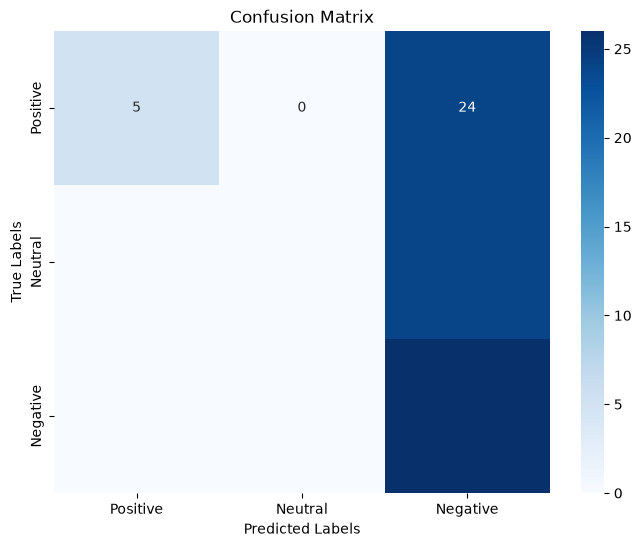

In [37]:
# Predict on the test set
y_pred = model.predict(x_test_padded)  # Probabilities for each class
y_pred_labels = np.argmax(y_pred, axis=1)  # Convert probabilities to class labels
y_true_labels = np.argmax(y_test_categorical, axis=1)  # True labels from one-hot encoding

# Generate Classification Report
print("\nClassification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=list(sentiment_labels.keys())))

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_true_labels, y_pred_labels)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=list(sentiment_labels.keys()), yticklabels=list(sentiment_labels.keys()))
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()

### Part 2: Build Model to train a sentiment analysis using an LSTM

In this section, we'll build and compile an LSTM model for sentiment classification.

### Part 3: Evaluating Model

In this section, we'll evaluate the model's performance using comprehensive metrics and visualizations.

This walkthrough provided hands-on experience with deep learning for natural language processing, specifically sentiment analysis using LSTM networks, which is crucial for understanding customer feedback in retail environments.